In [1]:
# Внимание!!! Важно, что бы файлы с данными и исполняемый файл находились в одной папке, 
# тогда пути к тестовым и тренировочным наборам будут содержать только имена файлов.
# 
# В пути к тренировочным и тестовым данным запрежается использовать абсалютную адресацию, 
# то есть адресацию, в которой присутствуют имена папок. Путь должен содержать только имя файла.
#
# Напоминание: под моделью машинного обучения понимаются все действия с исходными данными, 
# которые необходимо произвести, что бы сопоставить признаки целевому значению.

### Область работы 1 (библиотеки)

In [2]:
# Данный блок в области 1 НЕ выполняется преподавателем
# 
# данный блок предназначен только для подключения необходимых библиотек
# запрещается подключать библиотеки в других блоках
#
# установка дополнительных библиотек размещается прямо здесь (обязательно закоментированы)
#
# pip install

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import pandas.plotting as pd_plt
import matplotlib.colors as plt_colors
from IPython.display import display, display_html

from sklearn.linear_model import Ridge, SGDRegressor, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler, RobustScaler, QuantileTransformer, MinMaxScaler
from sklearn.preprocessing import OrdinalEncoder,LabelEncoder, OneHotEncoder, TargetEncoder, KBinsDiscretizer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold, StratifiedShuffleSplit, StratifiedKFold
from sklearn.model_selection import validation_curve
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.compose import ColumnTransformer, make_column_transformer, TransformedTargetRegressor
from sklearn.base import BaseEstimator, TransformerMixin
import category_encoders as ce
from sklearn.datasets import make_regression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler, RobustScaler, QuantileTransformer, FunctionTransformer, MinMaxScaler
from sklearn.preprocessing import OrdinalEncoder,LabelEncoder, OneHotEncoder, TargetEncoder, KBinsDiscretizer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold, StratifiedShuffleSplit, StratifiedKFold
from sklearn.model_selection import validation_curve
from sklearn.metrics import root_mean_squared_log_error, make_scorer, mean_squared_error
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.compose import ColumnTransformer, make_column_transformer, TransformedTargetRegressor
from sklearn.base import BaseEstimator, TransformerMixin
import category_encoders as ce
from sklearn.datasets import make_regression
from sklearn.preprocessing import PolynomialFeatures


### Область работы 2 (поиск  модели .... )

In [4]:
# Данный блок(и) НЕ выполняются преподавателем в области 2
# блок(и) предназначены для поиска лучшей модели 
# должен быть понятен и очевиден отбор параметров модели
# 
# Запрещается размещать данные блоки за пределами обасти 2
# Все блоки данной области должны быть выполнены
#
# ЗАПРЕЩАЕТСЯ ИСПОЛЬЗОВАТЬ ТЕСТОВЫЙ НАБОР
#
# Путь к тренировочному набору
# 

path_train = 'train.csv' # содержит только имя файла, без имен папок !!!

In [5]:
df = pd.read_csv(path_train)
df

,BCS,Age,Sex,Length,Girth,Height,Weight
0,3.0,5-10,stallion,99,114,100,152
1,3.0,5-10,female,91,123,97,173
2,3.0,10-15,gelding,99,123,106,171
3,2.5,2-5,female,92,105,96,121
4,3.0,<2,female,86,105,92,100
...,...,...,...,...,...,...,...
375,3.0,>20,female,94,120,104,152
376,3.0,<2,stallion,68,92,86,72
377,3.0,10-15,female,104,122,101,163
378,3.0,10-15,female,101,125,103,190


In [6]:
df.info() #видим, что NA нет 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   BCS     380 non-null    float64
 1   Age     380 non-null    object 
 2   Sex     380 non-null    object 
 3   Length  380 non-null    int64  
 4   Girth   380 non-null    int64  
 5   Height  380 non-null    int64  
 6   Weight  380 non-null    int64  
dtypes: float64(1), int64(4), object(2)
memory usage: 20.9+ KB


In [7]:
df.describe()

,BCS,Length,Girth,Height,Weight
count,380.000000,380.000000,380.000000,380.000000,380.000000
mean,2.901316,95.636842,116.026316,101.473684,153.021053
std,0.431446,7.499496,7.737060,4.460538,27.465682
min,1.000000,46.000000,66.000000,71.000000,27.000000
25%,2.500000,92.000000,113.000000,99.000000,139.750000
50%,3.000000,97.000000,117.000000,102.000000,157.000000
75%,3.000000,100.000000,121.000000,104.000000,172.000000
max,4.500000,112.000000,134.000000,113.000000,227.000000


In [8]:
print('количество строк дубликатов:', df.duplicated().sum())

количество строк дубликатов: 0


### Задача регрессии: предсказываем вес осла - Weight

<Axes: xlabel='Weight', ylabel='Percent'>

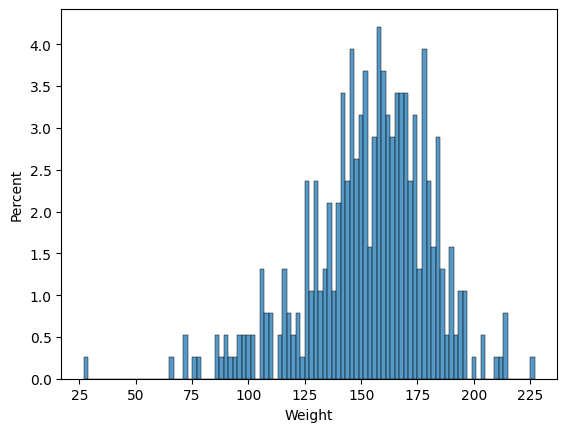

In [9]:
sns.histplot(data=df, x="Weight", bins=100, stat='percent')

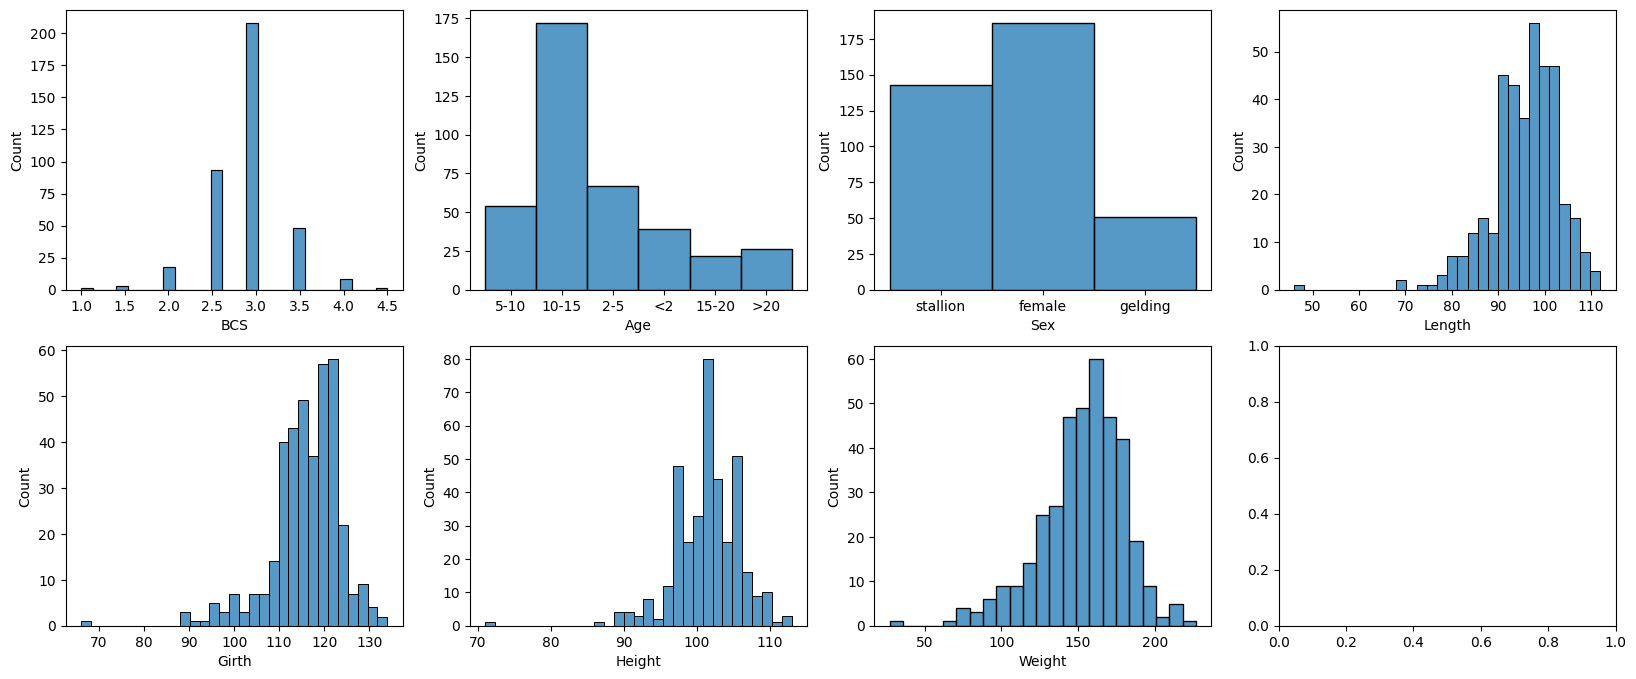

In [10]:
# рисуем распределение признаков
Col = df.columns
fig, axs = plt.subplots(2, 4, figsize=(20, 8))

for i, col in enumerate(Col):
    sns.histplot(x=df[col], ax=axs[i // 4, i % 4])

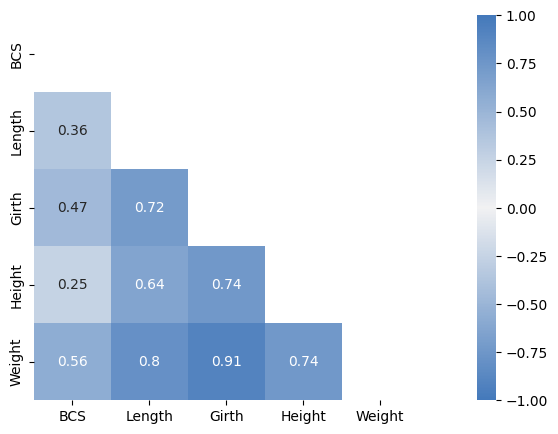

In [11]:
#матрица корреляций 
num = ['BCS','Length','Girth','Height','Weight']

corr = df[num].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(15, 5))
sns.heatmap(corr,
    mask=mask,
    cmap=sns.diverging_palette(250, 250, as_cmap=True),
    annot = True,
    vmin=-1.0, vmax=1.0,
    square=True,
    ax=ax);

In [12]:
X = df.drop(['Weight'], axis=1)
y = df['Weight']

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.75, test_size=0.25)

In [14]:
#Пишем ColumnTransformer, чтобы преобразовать данные 

num = ['BCS', 'Length', 'Girth', 'Height'] #числовые
cat = ['Age', 'Sex'] #категориальные

num_transformer = Pipeline(steps=[ 
    ('polynom', PolynomialFeatures(3, include_bias=False, interaction_only=True)),# Добавляем PolynomialFeatures(перемножение признаков до 3 степени)
    ('scaler', StandardScaler())]) #стандартизируем


cat_transformer = Pipeline(steps=[
    ('ce', OneHotEncoder(sparse_output=False)), #перекодируем категориальные признаки в числовые
    ('scaler', StandardScaler()) #стандартизируем
])


#соединяем весь СТ - указываем какие преобразования к каким признакам(строкам)
CT = ColumnTransformer([
    ("num", num_transformer, num),
    ("cat", cat_transformer, cat)
],remainder="passthrough",verbose_feature_names_out= False).set_output(transform="pandas")

display(CT)

res_ct = CT.fit_transform(X_train)

res_ct

ColumnTransformer(remainder='passthrough',
                  transformers=[('num',
                                 Pipeline(steps=[('polynom',
                                                  PolynomialFeatures(degree=3,
                                                                     include_bias=False,
                                                                     interaction_only=True)),
                                                 ('scaler', StandardScaler())]),
                                 ['BCS', 'Length', 'Girth', 'Height']),
                                ('cat',
                                 Pipeline(steps=[('ce',
                                                  OneHotEncoder(sparse_output=False)),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'Sex'])],
                  verbose_feature_names_out=False)

,BCS,Length,Girth,Height,BCS Length,BCS Girth,BCS Height,Length Girth,Length Height,Girth Height,...,Length Girth Height,Age_10-15,Age_15-20,Age_2-5,Age_5-10,Age_<2,Age_>20,Sex_female,Sex_gelding,Sex_stallion
61,-0.930480,0.156199,0.358506,1.649593,-0.691983,-0.659462,-0.472189,0.255570,0.783228,0.978661,...,0.674113,1.139468,-0.267261,-0.455661,-0.409918,-0.336573,-0.296287,-1.017700,-0.374166,1.309307
272,-0.930480,-0.903724,-1.742765,-0.360481,-1.067024,-1.293185,-0.934359,-1.432523,-0.825653,-1.332142,...,-1.288864,-0.877603,-0.267261,-0.455661,-0.409918,2.971125,-0.296287,0.982607,-0.374166,-0.763763
319,0.222506,0.288690,-0.429470,0.532885,0.273747,-0.001973,0.339177,-0.077644,0.416830,-0.075951,...,0.061968,-0.877603,-0.267261,-0.455661,2.439512,-0.336573,-0.296287,0.982607,-0.374166,-0.763763
228,0.222506,0.156199,0.621165,0.086202,0.217491,0.378261,0.215932,0.393402,0.130251,0.434485,...,0.323390,-0.877603,-0.267261,-0.455661,2.439512,-0.336573,-0.296287,0.982607,-0.374166,-0.763763
170,0.222506,0.686161,0.095847,0.309544,0.442515,0.188144,0.277555,0.450240,0.619744,0.182728,...,0.438225,1.139468,-0.267261,-0.455661,-0.409918,-0.336573,-0.296287,0.982607,-0.374166,-0.763763
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
233,-0.930480,-1.301196,-0.560800,-0.807164,-1.207664,-0.936716,-1.037064,-1.102152,-1.279564,-0.747303,...,-1.132303,-0.877603,-0.267261,-0.455661,2.439512,-0.336573,-0.296287,-1.017700,-0.374166,1.309307
295,-0.930480,-1.831158,-1.874095,-1.253848,-1.395185,-1.332793,-1.139768,-2.003036,-1.814255,-1.771635,...,-1.942770,-0.877603,-0.267261,-0.455661,-0.409918,2.971125,-0.296287,0.982607,-0.374166,-0.763763
313,0.222506,0.421180,0.621165,0.309544,0.330003,0.378261,0.277555,0.565338,0.421639,0.539168,...,0.534141,1.139468,-0.267261,-0.455661,-0.409918,-0.336573,-0.296287,-1.017700,-0.374166,1.309307
286,0.222506,0.553671,-0.166811,-0.137140,0.386259,0.093085,0.154309,0.225019,0.328356,-0.194476,...,0.118325,-0.877603,-0.267261,-0.455661,2.439512,-0.336573,-0.296287,-1.017700,2.672612,-0.763763


### В этой решетке рассматриваем несколько линейных моделей(пока без настройки параметров в каждой) - model__regressor__estimator, а также смотрим, будет ли влиять на метрику преобразование целевой переменной - model__transformer

In [15]:
model_pipe = Pipeline([
                ('model', TransformedTargetRegressor(
                        regressor = Pipeline(steps=[
                                ('preproc', CT),
                                ('estimator', Ridge())
                            ]),
                        transformer=PowerTransformer(),
                        check_inverse = False)
                )])

param_grid = [
    {'model__regressor__estimator':[Ridge(), SGDRegressor(), ElasticNet(max_iter=10000), Lasso(max_iter=10000)],
     'model__transformer':[PowerTransformer(method='yeo-johnson'), 
                           QuantileTransformer(output_distribution='normal', n_quantiles=200),
                           None]}
]

scorer = make_scorer(mean_squared_error)

grid = GridSearchCV(model_pipe, n_jobs=1, param_grid=param_grid, scoring=scorer)
grid.fit(X_train, y_train) 
grid_result = pd.DataFrame(grid.cv_results_).sort_values(["mean_test_score",'std_test_score']).T
grid_result

,11,5,2,8,1,4,7,6,9,10,0,3
mean_fit_time,0.006057,0.004644,0.004379,0.00487,0.005463,0.004756,0.005144,0.005516,0.005313,0.005019,0.011713,0.006213
std_fit_time,0.00041,0.000127,0.000128,0.000328,0.001078,0.000037,0.000328,0.000747,0.000306,0.00033,0.012394,0.002033
mean_score_time,0.004394,0.004159,0.00413,0.004232,0.004282,0.004159,0.004383,0.004294,0.004691,0.004407,0.004773,0.004261
std_score_time,0.000328,0.000188,0.000108,0.000281,0.000167,0.000096,0.00024,0.00035,0.000655,0.000315,0.000749,0.00016
param_model__regressor__estimator,Lasso(max_iter=10000),SGDRegressor(),Ridge(),ElasticNet(max_iter=10000),Ridge(),SGDRegressor(),ElasticNet(max_iter=10000),ElasticNet(max_iter=10000),Lasso(max_iter=10000),Lasso(max_iter=10000),Ridge(),SGDRegressor()
param_model__transformer,None,None,None,None,"QuantileTransformer(n_quantiles=200, output_di...","QuantileTransformer(n_quantiles=200, output_di...","QuantileTransformer(n_quantiles=200, output_di...",PowerTransformer(),PowerTransformer(),"QuantileTransformer(n_quantiles=200, output_di...",PowerTransformer(),PowerTransformer()
params,{'model__regressor__estimator': Lasso(max_iter...,{'model__regressor__estimator': SGDRegressor()...,"{'model__regressor__estimator': Ridge(), 'mode...",{'model__regressor__estimator': ElasticNet(max...,"{'model__regressor__estimator': Ridge(), 'mode...",{'model__regressor__estimator': SGDRegressor()...,{'model__regressor__estimator': ElasticNet(max...,{'model__regressor__estimator': ElasticNet(max...,{'model__regressor__estimator': Lasso(max_iter...,{'model__regressor__estimator': Lasso(max_iter...,"{'model__regressor__estimator': Ridge(), 'mode...",{'model__regressor__estimator': SGDRegressor()...
split0_test_score,82.361493,80.647225,78.105482,95.417802,80.524522,99.707112,366.662391,414.066875,760.537907,777.373943,83.165712,107.727742
split1_test_score,76.651567,76.573803,77.928333,79.587291,75.644933,136.305615,233.585735,302.578084,692.02341,697.561404,78.657086,113.808941
split2_test_score,68.460474,78.871691,85.335156,74.132972,100.55222,107.961488,294.80072,365.688625,1001.674056,1003.441325,14490674659253913979013675614208.0,1604645313830956010689296265641984.0


#### лучшие модели: Lasso, SGDRegressor, Ridge без преобразования целевой (тк param_model__transformer = None)

## В этой решетке берем лучшие из линейных Lasso и Ridge, а также еще другие нелинейные модели

In [16]:
model_pipe = Pipeline(steps=[('preproc', CT),
                            ('estimator', Ridge()) ])

param_grid = [
    {'estimator':[SVR(), GradientBoostingRegressor(), RandomForestRegressor(), 
                                    Ridge(), Lasso(max_iter=10000)]}
]

scorer = make_scorer(mean_squared_error)

grid = GridSearchCV(model_pipe, n_jobs=1, param_grid=param_grid, scoring=scorer)#, return_train_score = True)
grid.fit(X_train, y_train) 
grid_result = pd.DataFrame(grid.cv_results_).sort_values(["mean_test_score", 'std_test_score']).T
grid_result

,4,3,1,2,0
mean_fit_time,0.004576,0.003256,0.073998,0.087175,0.006334
std_fit_time,0.000485,0.000098,0.052994,0.00173,0.002943
mean_score_time,0.002213,0.002189,0.002967,0.005029,0.00356
std_score_time,0.000107,0.000124,0.000127,0.000153,0.001088
param_estimator,Lasso(max_iter=10000),Ridge(),GradientBoostingRegressor(),RandomForestRegressor(),SVR()
params,{'estimator': Lasso(max_iter=10000)},{'estimator': Ridge()},{'estimator': GradientBoostingRegressor()},{'estimator': RandomForestRegressor()},{'estimator': SVR()}
split0_test_score,82.361493,78.105482,79.450733,81.602621,384.213749
split1_test_score,76.651567,77.928333,95.768087,96.75137,386.901467
split2_test_score,68.460474,85.335156,116.306512,119.301156,667.715945
split3_test_score,52.063449,51.315579,56.415726,53.085596,359.315058


#### видим распределение моделей от лучшей метрики к худшей

## Настраиваем параметры для Lasso

In [17]:
model_pipe = Pipeline(steps=[
                                ('preproc', CT),
                                ('estimator', Lasso(max_iter=1000000))
                            ])
param_grid = {'estimator__alpha': [0.001, 0.01, 0.1, 1, 10]}

scorer = make_scorer(mean_squared_error)
grid_ridge = GridSearchCV(model_pipe, param_grid=param_grid, scoring=scorer, cv=5)
grid_ridge.fit(X_train, y_train)

grid_result_ridge = pd.DataFrame(grid_ridge.cv_results_).sort_values(["mean_test_score",'std_test_score']).T
grid_result_ridge

,2,3,1,0,4
mean_fit_time,0.006785,0.004544,0.017157,0.400131,0.003533
std_fit_time,0.002583,0.000407,0.006577,0.155554,0.000128
mean_score_time,0.002322,0.002262,0.002761,0.002877,0.002275
std_score_time,0.00015,0.000057,0.000258,0.000091,0.000172
param_estimator__alpha,0.1,1.0,0.01,0.001,10.0
params,{'estimator__alpha': 0.1},{'estimator__alpha': 1},{'estimator__alpha': 0.01},{'estimator__alpha': 0.001},{'estimator__alpha': 10}
split0_test_score,78.529488,82.361493,78.50782,80.527815,224.529883
split1_test_score,77.335661,76.651567,78.082897,79.088982,160.037725
split2_test_score,70.221239,68.460474,96.995305,132.262728,217.677236
split3_test_score,51.047534,52.063449,51.477625,52.304394,169.523674


In [18]:
#итоговая модель с лучшими параметрами
model_pipe = Pipeline(steps=[('preproc', CT),
                            ('estimator', Lasso(max_iter=1000000, alpha = 0.01))
                            ])

model_pipe.fit(X_train, y_train)
y_pred = model_pipe.predict(X_test)

print("MSE на тестовом наборе: ", mean_squared_error(y_test, y_pred))

MSE на тестовом наборе:  66.2296104121917


## Настраиваем параметры для Ridge

In [19]:
model_pipe_ridge = Pipeline(steps=[
                                ('preproc', CT),
                                ('estimator', Ridge(max_iter=100000))
                            ])
param_grid_ridge = [
    {'estimator':[Ridge()],
     'estimator__alpha': [0.00001, 0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1, 5]}
     #'estimator__solver': ['auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga']}
]


grid_ridge = GridSearchCV(model_pipe_ridge, param_grid=param_grid_ridge, scoring=scorer, cv=5)
grid_ridge.fit(X_train, y_train)

grid_result_ridge = pd.DataFrame(grid_ridge.cv_results_).sort_values(["mean_test_score",'std_test_score']).T
grid_result_ridge

,8,7,1,6,2,5,4,3,0
mean_fit_time,0.003321,0.003418,0.003567,0.003775,0.003371,0.003331,0.003332,0.003342,0.006146
std_fit_time,0.000041,0.000096,0.000154,0.000901,0.000058,0.000152,0.000065,0.000118,0.003338
mean_score_time,0.002197,0.002212,0.002317,0.002216,0.002273,0.002174,0.002184,0.002246,0.003174
std_score_time,0.000048,0.000062,0.000092,0.000046,0.000148,0.000045,0.000027,0.00014,0.000458
param_estimator,Ridge(),Ridge(),Ridge(),Ridge(),Ridge(),Ridge(),Ridge(),Ridge(),Ridge()
param_estimator__alpha,5.0,1.0,0.0001,0.5,0.001,0.1,0.05,0.01,0.00001
params,"{'estimator': Ridge(), 'estimator__alpha': 5}","{'estimator': Ridge(), 'estimator__alpha': 1}","{'estimator': Ridge(), 'estimator__alpha': 0.0...","{'estimator': Ridge(), 'estimator__alpha': 0.5}","{'estimator': Ridge(), 'estimator__alpha': 0.001}","{'estimator': Ridge(), 'estimator__alpha': 0.1}","{'estimator': Ridge(), 'estimator__alpha': 0.05}","{'estimator': Ridge(), 'estimator__alpha': 0.01}","{'estimator': Ridge(), 'estimator__alpha': 1e-05}"
split0_test_score,79.411555,78.105482,79.03106,78.03973,80.634928,78.765757,79.268367,80.274004,75.886945
split1_test_score,77.728866,77.928333,77.155102,78.020756,78.61926,78.294738,78.467068,78.897459,79.582737
split2_test_score,77.6821,85.335156,87.374286,93.939888,93.000701,120.450097,127.974531,129.684616,183.757035


In [20]:
#при бОльшем уменьшении альфа, метрика почти не улучшается, оставим 0.001
model_pipe = Pipeline(steps=[('preproc', CT),
                            ('estimator', Ridge(max_iter=100000, alpha = 0.0001))
                            ])

model_pipe.fit(X_train, y_train)
y_pred = model_pipe.predict(X_test)

y_train_pred = model_pipe.predict(X_train)

print('MSE на обучающем наборе: {:.3f}'.format(mean_squared_error(y_train, y_train_pred)))
print("MSE на тестовом наборе: ", mean_squared_error(y_test, y_pred))

MSE на обучающем наборе: 56.487
MSE на тестовом наборе:  71.76639202442502


## Настроим параметры для GradientBoostingRegressor

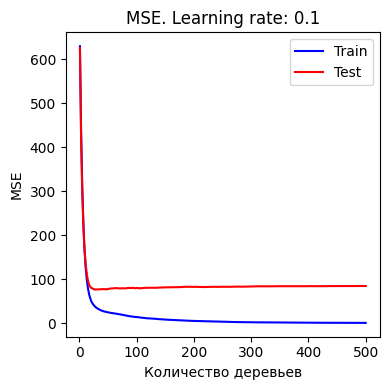

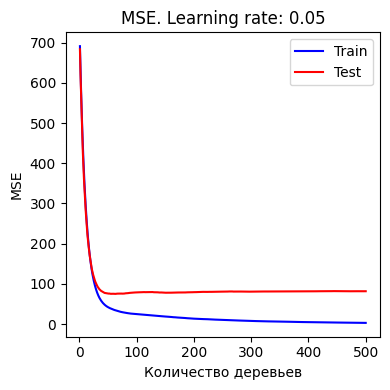

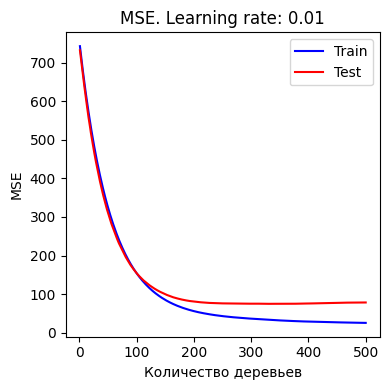

In [21]:
# в этом блоке выбираем learning_rate и n_estimators(смотрим на картинке, 
#где линия ниже, чтобы получить наименьшее MSE)

def plot_learnig_tree_new(estimator, X_train, X_test, y_train, y_test, CT, learning_rate=None):
    gb_estimator = estimator.named_steps['estimator']
    n_estimators = gb_estimator.n_estimators
    zero = np.zeros(n_estimators, dtype=np.float64)
    color_one = 'blue'
    color_two = 'red'

    X_train_transformed = CT.transform(X_train)
    X_test_transformed = CT.transform(X_test)

    train_score = zero
    for i, y_pred_train in enumerate(gb_estimator.staged_predict(X_train_transformed)):
        train_score[i] = mean_squared_error(y_train, y_pred_train)

    fig, ax1 = plt.subplots(figsize=(4, 4))

    ax1 = plt.subplot(111) # Убрали второй subplot
    ax1.plot(
        (np.arange(train_score.shape[0]) + 1),
        train_score,
        "-",
        color=color_one,
        label='Train',
    )

    test_score = zero
    for i, y_pred_test in enumerate(gb_estimator.staged_predict(X_test_transformed)):
        test_score[i] = mean_squared_error(y_test, y_pred_test)

    ax1.plot(
        (np.arange(test_score.shape[0]) + 1),
        test_score,
        "-",
        color=color_two,
        label='Test',
    )
    ax1.legend(loc='best')
    ax1.set_title(f'MSE. Learning rate: {learning_rate}')
    ax1.set_xlabel('Количество деревьев')
    ax1.set_ylabel('MSE')

    plt.tight_layout()
    plt.show()


# Обучение моделей
clf = Pipeline(steps=[
                    ('preproc', CT),
                    ('estimator', GradientBoostingRegressor(n_estimators=500, learning_rate=0.1))
                            ]) 
clf.fit(X_train, y_train)
plot_learnig_tree_new(clf, X_train, X_test, y_train, y_test, CT, learning_rate=0.1)

clf2 = Pipeline(steps=[
                    ('preproc', CT),
                    ('estimator', GradientBoostingRegressor(n_estimators=500, learning_rate=0.05))
                            ])
clf2.fit(X_train, y_train)
plot_learnig_tree_new(clf2, X_train, X_test, y_train, y_test, CT, learning_rate=0.05)

clf3 = Pipeline(steps=[
                    ('preproc', CT),
                    ('estimator', GradientBoostingRegressor(n_estimators=500, learning_rate=0.01))
                            ]) 
clf3.fit(X_train, y_train)
plot_learnig_tree_new(clf3, X_train, X_test, y_train, y_test, CT, learning_rate=0.01)

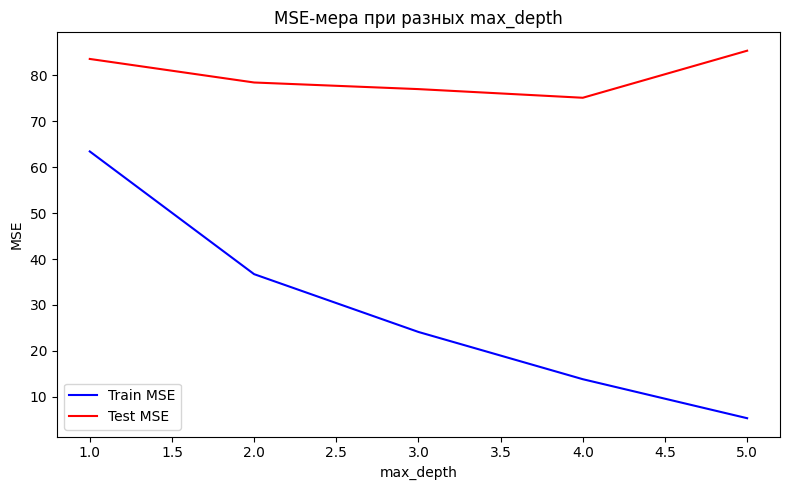

In [22]:
#выбрали n_estimators и learning_rate
#учитывая это, выбираем max_depths
original_params = {
    "n_estimators": 50, 
    "learning_rate": 0.1
}

max_depths = range(1, 6)

fig, ax = plt.subplots(figsize=(8, 5))

train_mse = []
test_mse = []

for depth in max_depths:
    params = dict(original_params)
    params["max_depth"] = depth
    clf = Pipeline(steps=[
                    ('preproc', CT),
                    ('estimator', GradientBoostingRegressor(**params))
                            ]) 
    clf.fit(X_train, y_train)

    train_pred = clf.predict(X_train)
    test_pred = clf.predict(X_test)

    train_mse.append(mean_squared_error(y_train, train_pred))
    test_mse.append(mean_squared_error(y_test, test_pred))

ax.plot(max_depths, train_mse, label="Train MSE", color="blue")
ax.plot(max_depths, test_mse, label="Test MSE", color="red")
ax.set_xlabel("max_depth")
ax.set_ylabel("MSE")
ax.legend()
ax.set_title("MSE-мера при разных max_depth")


plt.tight_layout()
plt.show()

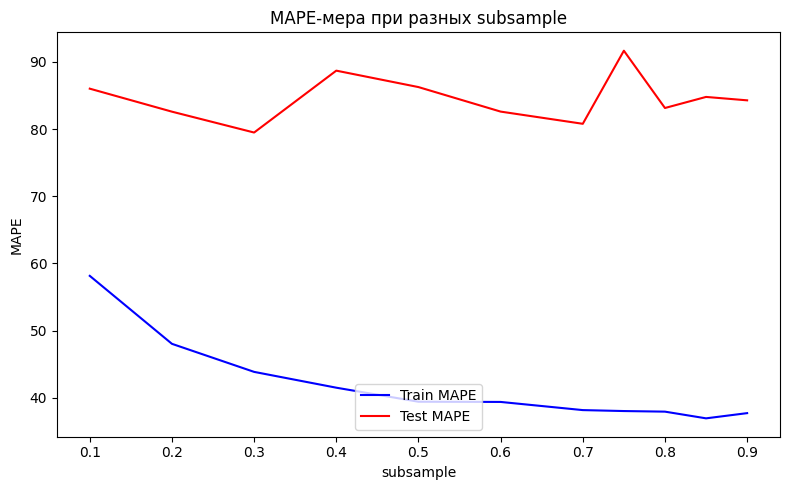

In [23]:
#учитывая все предыдущее, выбираем subsamples
original_params = {
    "n_estimators": 50,
    "learning_rate": 0.1,
    "max_depth": 2 
}

subsamples = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9] 

fig, ax = plt.subplots(figsize=(8, 5))

train_mse = []
test_mse = []

for subsample_val in subsamples:
    params = dict(original_params)
    params["subsample"] = subsample_val
    clf = Pipeline(steps=[
                    ('preproc', CT),
                    ('estimator', GradientBoostingRegressor(**params))
                            ]) 
    clf.fit(X_train, y_train)

    train_pred = clf.predict(X_train)
    test_pred = clf.predict(X_test)

    train_mse.append(mean_squared_error(y_train, train_pred))
    test_mse.append(mean_squared_error(y_test, test_pred))


ax.plot(subsamples, train_mse, label="Train MAPE", color="blue")
ax.plot(subsamples, test_mse, label="Test MAPE", color="red")
ax.set_xlabel("subsample")
ax.set_ylabel("MAPE")
ax.legend(loc='lower center')
ax.set_title("MAPE-мера при разных subsample")


plt.tight_layout()
plt.show()

### Итоговая модель с выбранными параметрами

In [24]:
gbrt = Pipeline(steps=[('preproc', CT),
                       ('estimator', GradientBoostingRegressor(n_estimators = 50, learning_rate = 0.1, 
                                                               max_depth = 2, subsample=0.5)) ]) 
gbrt.fit(X_train, y_train)

y_train_pred = gbrt.predict(X_train)
y_pred_gbrt = gbrt.predict(X_test)

print('MSE на обучающем наборе: {:.3f}'.format(mean_squared_error(y_train, y_train_pred)))
print('MSE на тестовом наборе: {:.3f}'.format(mean_squared_error(y_test, y_pred_gbrt)))

MSE на обучающем наборе: 39.745
MSE на тестовом наборе: 91.658
